## **Relationships**

In [141]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import seaborn as sns

In [142]:
# Load data

# Inflation
infl = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/inflation/Inflation.xlsx")

# Exchange Rates
eur_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/EUR_CZK.xlsx")
usd_czk = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/exchange_rates/USD_CZK.xlsx")

# Stocks
pxtr = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/CZStocks.xlsx", sheet_name="PXTR")
sx5gt = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/EUStocks.xlsx", sheet_name="SX5GT")
spxtr = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/USStocks.xlsx", sheet_name="SPXTR")

# Bonds
czbond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/CZBonds10YR.xlsx")
eubond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/DEBonds10YR.xlsx")
usbond = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/bonds/USBonds10YR.xlsx")

In [143]:
# Shift Exchange rates one year lower to correspond to the rest of the data
eur_czk.loc[:, "Year"]=eur_czk["Year"]-1
usd_czk.loc[:, "Year"]=usd_czk["Year"]-1

In [144]:
# Prepare column names

# Exchange rates
eur_czk.rename({"Log_return": "EUR"}, axis=1, inplace=True)
eur_czk=eur_czk[["Year", "EUR"]]
usd_czk.rename({"Log_return": "USD"}, axis=1, inplace=True)
usd_czk=usd_czk[["Year", "USD"]]

# Stocks
pxtr.rename({"Log_return": "PXTR"}, axis=1, inplace=True)
pxtr=pxtr[["Year", "PXTR"]]
sx5gt.rename({"Log_return": "SX5GT"}, axis=1, inplace=True)
sx5gt=sx5gt[["Year", "SX5GT"]]
spxtr.rename({"Log_return": "SPXTR"}, axis=1, inplace=True)
spxtr=spxtr[["Year", "SPXTR"]]

# Bonds
czbond.rename({"Log_return": "CZBond"}, axis=1, inplace=True)
czbond=czbond[["Year", "CZBond"]]
eubond.rename({"Log_return": "EUBond"}, axis=1, inplace=True)
eubond=eubond[["Year", "EUBond"]]
usbond.rename({"Log_return": "USBond"}, axis=1, inplace=True)
usbond=usbond[["Year", "USBond"]]

In [145]:
# List of all dataframes (except for inflation)
df_list = [eur_czk, usd_czk, pxtr, sx5gt, spxtr, czbond, eubond, usbond]

# Outer join all data
data = df_list[0]
for df in df_list[1:]:
    data = pd.merge(data, df, on='Year', how='outer')
    
# Set "Year" as an index
data.set_index("Year", inplace=True)

In [146]:
# Compute Correlation matrix
corr_matrix = data.corr()

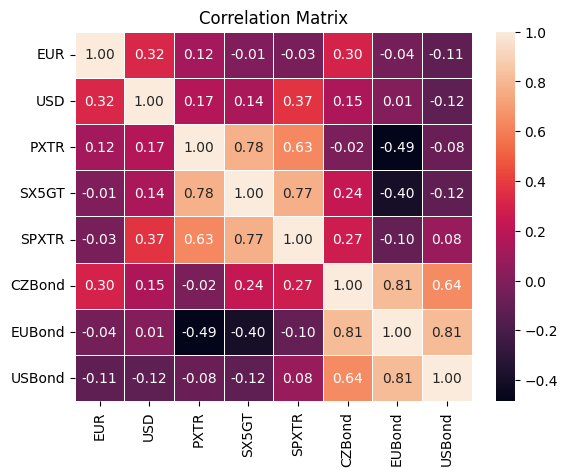

In [147]:
# Visualize Correlation Matrix
plt.Figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
#plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Relationships/Corr_matrix.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [148]:
# Cholesky decomposition calculation from covariance matrix
chol_deco_all = np.linalg.cholesky(data.cov())

# Save matrix
#np.save("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/cholesky_decomposition_all.npy", chol_deco_all)

# Visualize
chol_deco = pd.DataFrame(chol_deco_all)
chol_deco.columns = ['']*chol_deco.shape[1]
print(chol_deco.to_string(index=False))

                                                                           
 0.038190  0.000000  0.000000  0.000000 0.000000 0.000000 0.000000 0.000000
 0.029359  0.099974  0.000000  0.000000 0.000000 0.000000 0.000000 0.000000
 0.018607  0.014615  0.163453  0.000000 0.000000 0.000000 0.000000 0.000000
-0.000691  0.017658  0.098771  0.090073 0.000000 0.000000 0.000000 0.000000
-0.004855  0.058103  0.077983  0.052629 0.093851 0.000000 0.000000 0.000000
 0.021202  0.002113 -0.003984  0.026899 0.016643 0.059962 0.000000 0.000000
-0.001634  0.000992 -0.017367 -0.001128 0.007866 0.029981 0.027358 0.000000
-0.006527 -0.005864 -0.003411 -0.004008 0.016026 0.039971 0.018664 0.037177


In [149]:
# Check that Covariance Matrix is positive definite
np.all(np.linalg.eigvals(data.cov()) > 0) 

np.True_

In [150]:
# Cholesky decomposition of CZ assets only
# Truncate data table to cz only
cz_data = data[["PXTR", "CZBond"]]
# Generate cholesky
chol_deco_cz = np.linalg.cholesky(cz_data.cov())
# Save matrix
#np.save("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/cholesky_decomposition_cz.npy", chol_deco_cz)
# Visualize
chol_deco_cz = pd.DataFrame(chol_deco_cz)
chol_deco_cz.columns = ['']*chol_deco_cz.shape[1]
print(chol_deco_cz.to_string(index=False))

                  
 0.165157 0.000000
-0.001367 0.071162


In [151]:
# Check that Covariance Matrix is positive definite
np.all(np.linalg.eigvals(cz_data.cov()) > 0) 

np.True_

In [152]:
# Cholesky decomposition of foreign assets only
# Truncate data table to cz only
foreign_data = data[data.columns[~data.columns.isin(["PXTR", "CZBond"])]]
# Generate cholesky
chol_deco_foreign = np.linalg.cholesky(foreign_data.cov())
# Save matrix
#np.save("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/cholesky_decomposition_foreign.npy", chol_deco_foreign)
# Visualize
chol_deco_foreign = pd.DataFrame(chol_deco_foreign)
chol_deco_foreign.columns = ['']*chol_deco_foreign.shape[1]
print(chol_deco_foreign.to_string(index=False))

                                                        
 0.038190  0.000000  0.000000 0.000000 0.000000 0.000000
 0.029359  0.099974  0.000000 0.000000 0.000000 0.000000
-0.000691  0.017658  0.133675 0.000000 0.000000 0.000000
-0.004855  0.058103  0.093084 0.094840 0.000000 0.000000
-0.001634  0.000992 -0.013593 0.006219 0.042292 0.000000
-0.006527 -0.005864 -0.005221 0.015954 0.040873 0.040747


In [153]:
# Check that Covariance Matrix is positive definite
np.all(np.linalg.eigvals(foreign_data.cov()) > 0) 

np.True_